In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import contextily
from pathlib import Path

vis_dir = Path("../visualizations")

In [2]:
sf = gpd.read_parquet("../data/processed/sf_parcels_acs.parquet")

sf["acres_geom"] = sf.geometry.area / 43560   # CRS is in US feet, 43,560 sq ft per acre

sf["pop_other"] = sf["pop_total"] - sf["pop_nh_white"] - sf["pop_nh_black"] - sf["pop_nh_asian"] - sf["pop_hispanic"]
sf["pop_other"] = sf["pop_other"].clip(lower=0)

sf["pct_nonwhite"] = 100 - sf["pct_nh_white"]

race_groups = ["White", "Asian", "Hispanic/Latino", "Black", "Other"]
print(len(sf), "parcels")

128637 parcels


In [3]:
cols = ["GEOID", "pop_total", "pop_nh_white", "pop_nh_asian", "pop_hispanic", "pop_nh_black", "pop_other"]
bg = sf[cols].dropna(subset=["GEOID"]).drop_duplicates("GEOID").set_index("GEOID")
bg = bg.rename(columns={"pop_nh_white": "White", "pop_nh_asian": "Asian", "pop_hispanic": "Hispanic/Latino",
                        "pop_nh_black": "Black", "pop_other": "Other"})

shares = bg[race_groups].div(bg["pop_total"], axis=0).fillna(0)

# find the largest group by checking each one
bg["largest_group"] = "No data"
bg["largest_share"] = 0.0
for grp in race_groups:
    bigger = shares[grp] > bg["largest_share"]
    bg.loc[bigger, "largest_group"] = grp
    bg.loc[bigger, "largest_share"] = shares[grp]

bg["is_majority"] = bg["largest_share"] > 0.5

# attach the result back onto the parcels
sf = sf.merge(bg[["largest_group", "largest_share", "is_majority"]], left_on="GEOID", right_index=True, how="left")
sf["largest_group"] = sf["largest_group"].fillna("No data")

print(len(bg), "block groups,", round(bg["is_majority"].mean() * 100), "% have a true majority group")
bg.groupby(["largest_group", "is_majority"]).size().unstack(fill_value=0)

623 block groups, 55 % have a true majority group


is_majority,False,True
largest_group,,
Asian,89,143
Black,7,2
Hispanic/Latino,42,14
No data,1,0
Other,4,0
White,135,186


In [9]:
colors = {
    "White":           "#2a78d6",
    "Asian":           "#eb6834",
    "Hispanic/Latino": "#1baf7a",
    "Black":           "#5b2a86",
    "Other":           "#8a8986",
}
no_data_color = "#d9d9d6"
LIGHT = 0.4

nonwhite_bins   = [0, 20, 40, 60, 80, 100]
nonwhite_labels = ["0–20%", "20–40%", "40–60%", "60–80%", "80–100%"]
nonwhite_colors = ["#fde0ef", "#f4a9cb", "#e0679c", "#b0306b", "#6e0d40"]

SCALE_COLORS = {0: "#A9A9A9", 1: "#f0f921", 2: "#fdb42f", 3: "#ed7953", 4: "#cc4778"}   # same as Eve's map

def add_basemap(ax):
    try:
        contextily.add_basemap(ax, crs=sf.crs, source=contextily.providers.Esri.WorldGrayCanvas)
    except Exception:
        print("basemap could not load (no internet?) - map drawn without it")

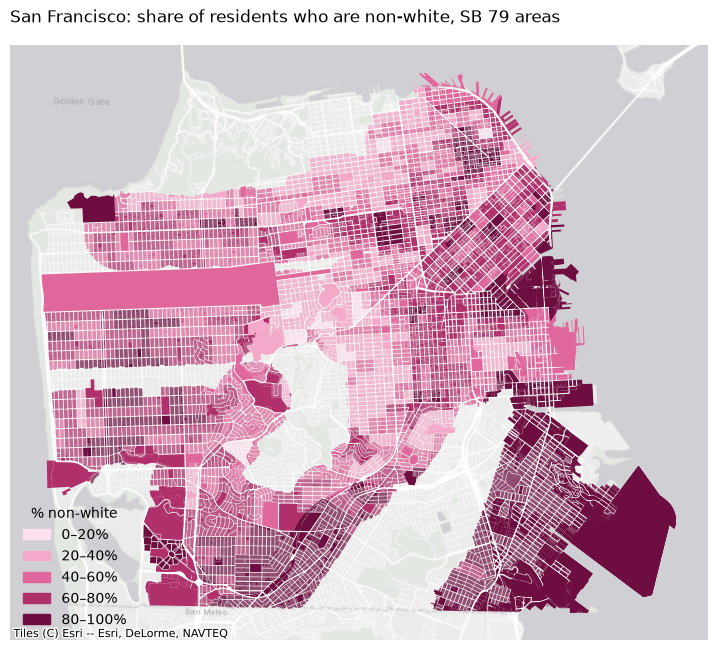

In [10]:
sf["nw_bin"] = pd.cut(sf["pct_nonwhite"], bins=nonwhite_bins, labels=nonwhite_labels, include_lowest=True)

def plot_nonwhite(ax, title):
    # one layer per bin, so each bin gets its own color
    for label, color in zip(nonwhite_labels, nonwhite_colors):
        sf[sf["nw_bin"] == label].plot(ax=ax, color=color, linewidth=0)
    sf[sf["nw_bin"].isna()].plot(ax=ax, color=no_data_color, linewidth=0)
    add_basemap(ax)

    handles = []
    for label, color in zip(nonwhite_labels, nonwhite_colors):
        handles.append(Patch(color=color, label=label))
    ax.legend(handles=handles, title="% non-white", loc="lower left", frameon=False)
    ax.set_title(title, loc="left")
    ax.set_axis_off()

fig, ax = plt.subplots(figsize=(9, 9))
plot_nonwhite(ax, "San Francisco: share of residents who are non-white, SB 79 areas")
plt.savefig(vis_dir / "sf_pct_nonwhite_map.png", dpi=150, bbox_inches="tight")
plt.show()

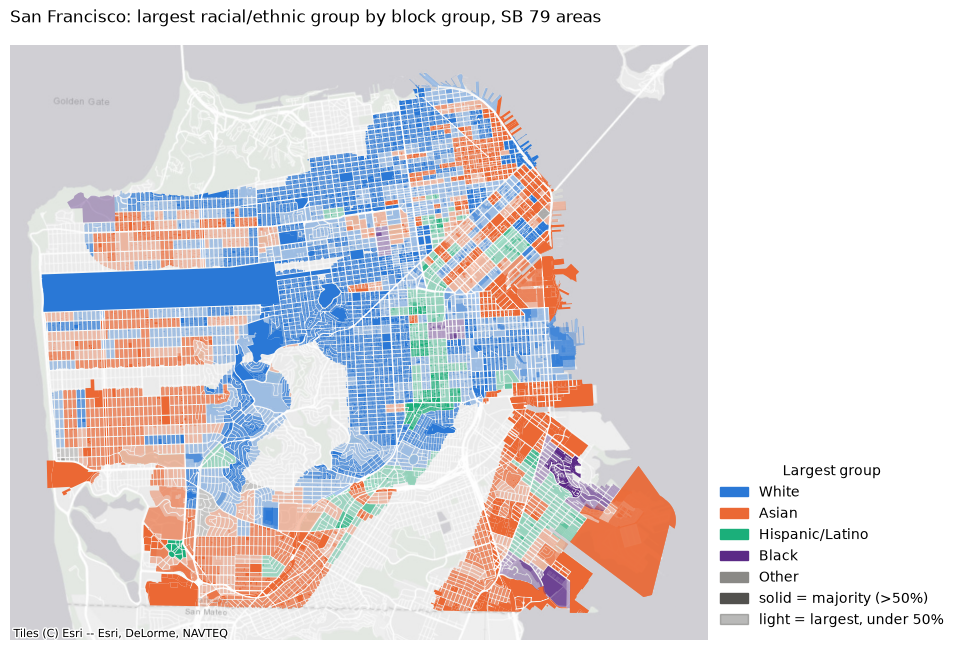

In [11]:
fig, ax = plt.subplots(figsize=(9, 9))

handles = []
for grp in race_groups:
    majority  = sf[(sf["largest_group"] == grp) & (sf["is_majority"] == True)]
    plurality = sf[(sf["largest_group"] == grp) & (sf["is_majority"] == False)]
    if len(majority) > 0:
        majority.plot(ax=ax, color=colors[grp], linewidth=0)
    if len(plurality) > 0:
        plurality.plot(ax=ax, color=colors[grp], alpha=LIGHT, linewidth=0)
    if len(majority) + len(plurality) > 0:
        handles.append(Patch(color=colors[grp], label=grp))
sf[sf["largest_group"] == "No data"].plot(ax=ax, color=no_data_color, linewidth=0)
add_basemap(ax)

handles.append(Patch(color="#52514e", label="solid = majority (>50%)"))
handles.append(Patch(color="#52514e", alpha=LIGHT, label="light = largest, under 50%"))
ax.legend(handles=handles, title="Largest group", loc="lower left", bbox_to_anchor=(1, 0), frameon=False)
ax.set_title("San Francisco: largest racial/ethnic group by block group, SB 79 areas", loc="left")
ax.set_axis_off()
plt.savefig(vis_dir / "sf_majority_race_map.png", dpi=150, bbox_inches="tight")
plt.show()

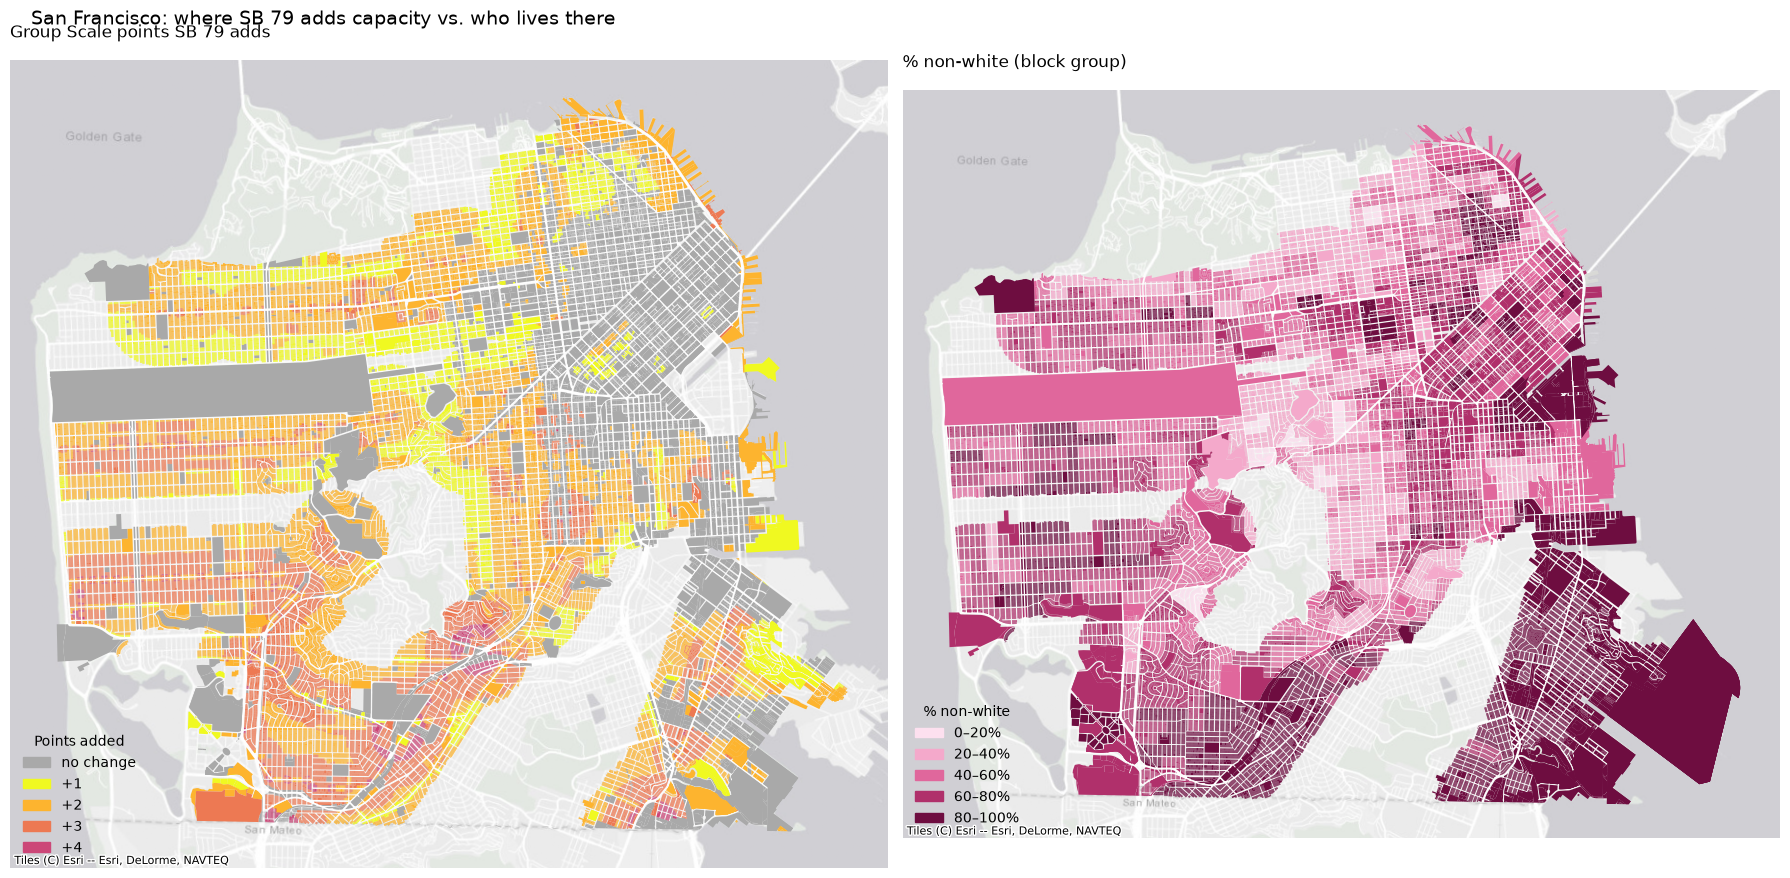

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(18, 9))

# left: Eve's points-added map
handles = []
for pts, color in SCALE_COLORS.items():
    layer = sf[sf["scale_change"] == pts]
    if len(layer) > 0:
        layer.plot(ax=axes[0], color=color, linewidth=0)
        if pts == 0:
            handles.append(Patch(color=color, label="no change"))
        else:
            handles.append(Patch(color=color, label="+" + str(pts)))
add_basemap(axes[0])
axes[0].legend(handles=handles, title="Points added", loc="lower left", frameon=False)
axes[0].set_title("Group Scale points SB 79 adds", loc="left")
axes[0].set_axis_off()

# right: % non-white
plot_nonwhite(axes[1], "% non-white (block group)")

plt.tight_layout(rect=(0, 0, 1, 0.95))
fig.suptitle("San Francisco: where SB 79 adds capacity vs. who lives there", x=0.02, ha="left", fontsize=14)
plt.savefig(vis_dir / "sf_scale_vs_nonwhite_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
def stacked_bars(ax, table, title):
    # table: one row per bar, one column per race group, values are percentages that add to 100
    bottom = pd.Series(0.0, index=table.index)
    for grp in race_groups:
        ax.bar(table.index, table[grp], bottom=bottom, color=colors[grp], label=grp,
               edgecolor="white", linewidth=1.5, width=0.6)
        # label segments big enough to read
        for i, bar_name in enumerate(table.index):
            value = table.loc[bar_name, grp]
            if value >= 7:
                ax.text(i, bottom[bar_name] + value / 2, str(round(value)) + "%",
                        ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        bottom = bottom + table[grp]
    ax.set_ylim(0, 100)
    ax.set_ylabel("% of residents")
    ax.set_title(title, loc="left")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)

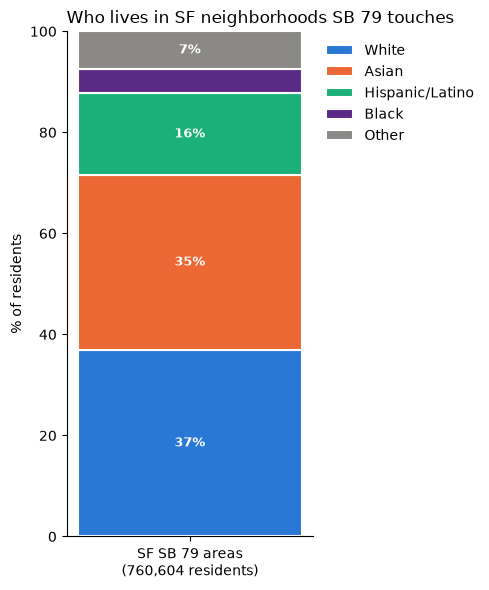

,White,Asian,Hispanic/Latino,Black,Other
"SF SB 79 areas\n(760,604 residents)",37.0,34.6,16.1,4.9,7.4


In [14]:
all_row = bg[race_groups].sum() / bg["pop_total"].sum() * 100
all_table = pd.DataFrame([all_row], index=["SF SB 79 areas\n(" + f"{int(bg['pop_total'].sum()):,}" + " residents)"])

fig, ax = plt.subplots(figsize=(5, 6))
stacked_bars(ax, all_table, "Who lives in SF neighborhoods SB 79 touches")
plt.tight_layout()
plt.savefig(vis_dir / "sf_race_breakdown_sb79_areas.png", dpi=150, bbox_inches="tight")
plt.show()
all_table.round(1)

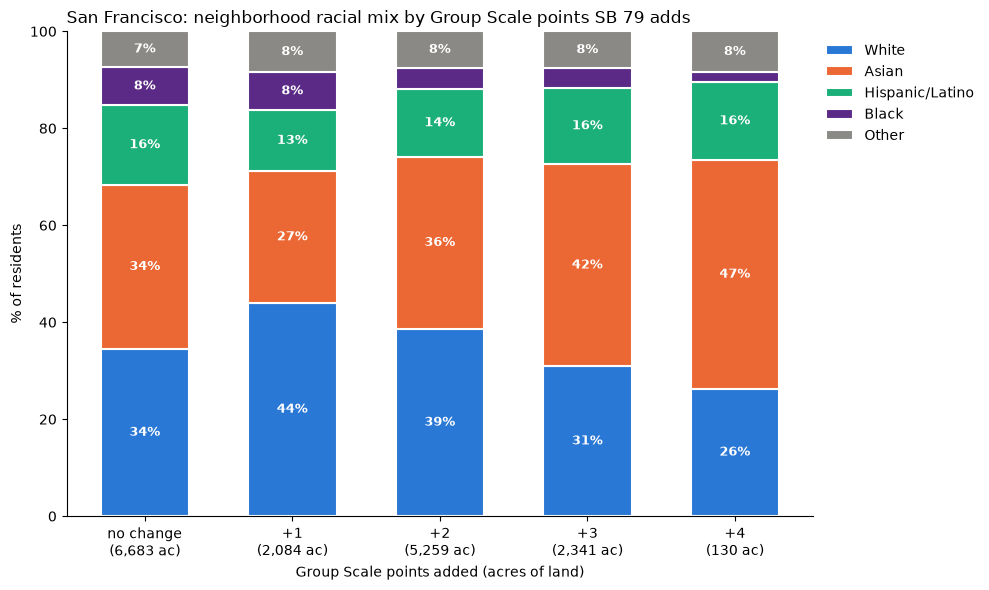

,White,Asian,Hispanic/Latino,Black,Other
"no change\n(6,683 ac)",34.5,33.9,16.3,7.9,7.4
"+1\n(2,084 ac)",44.0,27.1,12.7,7.7,8.5
"+2\n(5,259 ac)",38.6,35.5,13.9,4.4,7.6
"+3\n(2,341 ac)",30.9,41.7,15.8,4.0,7.6
+4\n(130 ac),26.3,47.1,16.2,2.0,8.4


In [15]:
g = sf[sf["pop_total"] > 0].dropna(subset=["scale_change"]).copy()
pop_cols = {"White": "pop_nh_white", "Asian": "pop_nh_asian", "Hispanic/Latino": "pop_hispanic",
            "Black": "pop_nh_black", "Other": "pop_other"}
for grp, col in pop_cols.items():
    g[grp] = g[col] / g["pop_total"] * g["acres_geom"]     # share x acres

totals = g.groupby("scale_change")[race_groups + ["acres_geom"]].sum()
pts_table = totals[race_groups].div(totals[race_groups].sum(axis=1), axis=0) * 100

# readable bar names like "+3 (2,341 ac)"
new_names = []
for pts in pts_table.index:
    acres = f"{totals.loc[pts, 'acres_geom']:,.0f}"
    if pts == 0:
        new_names.append("no change\n(" + acres + " ac)")
    else:
        new_names.append("+" + str(int(pts)) + "\n(" + acres + " ac)")
pts_table.index = new_names

fig, ax = plt.subplots(figsize=(10, 6))
stacked_bars(ax, pts_table, "San Francisco: neighborhood racial mix by Group Scale points SB 79 adds")
ax.set_xlabel("Group Scale points added (acres of land)")
plt.tight_layout()
plt.savefig(vis_dir / "sf_race_by_points_added.png", dpi=150, bbox_inches="tight")
plt.show()
pts_table.round(1)